# Introduction
League of Legends (LoL) is a multiplayer online battle arena (MOBA) game where two teams of five players compete in order to destroy the enemy team's Nexus. This project and analysis goes over LoL match data to analyze which in-game data, statistics, and objectives are the strongest indicators of predicting match outcomes, and whether the blue side holds a meaningful win rate advantage across ranks.

## Dataset
The data set used consists of six relational tables sourced from Kaggle containing around 279,000 matches across all ranked tiers. The data set was then filtered to be 110,521 matches after filtering out game matches that lasted less than 15 minutes. The most important key variables from this data set are team kills, towers destroyed, dragon kills, Baron Nashor kills, and rift herald kills, in addition to the match rank and duration.

The raw data is not included in this repository. See `data/README.md` for the source and download instructions.

## Project Questions
1. Does blue side hold a meaningful win rate advantage across all ranks?
2. Which objectives are the strongest predictors of the match outcomes?
3. Can a model be used to accurately predict game outcomes from end-of-game data?
4. Does the importance of objectives differ across rank tiers?
5. Do longer games change which objectives matter most for predicting outcomes?
# Data Wrangling, Munging, and Cleaning
## Importing Libraries and Loading Data

In [1]:
#all imports and other similar things from R but now in py
import pandas as pd
import numpy as np
import statsmodels.api as sm

import matplotlib.pyplot as plt
import seaborn as sns

#for the model
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')


In [2]:
# Load the data
match_tbl = pd.read_csv("data/MatchTbl.csv")
team_tbl = pd.read_csv("data/TeamMatchTbl.csv")
rank_tbl = pd.read_csv("data/RankTbl.csv")

#use left join in order to keep all rows from match table and add rank from rank table
ranked_matches = match_tbl.merge(rank_tbl, left_on='RankFk', right_on='RankId', how='left')

#use inner join to omit matches without match data
lol_data = ranked_matches.merge(team_tbl, left_on='MatchId', right_on='MatchFk', how='inner')
lol_data = lol_data[lol_data['QueueType'] == 'CLASSIC']
lol_data = lol_data[lol_data['RankName'] != 'Unranked']

The dataset contains six tables each linked by ID columns and values. Only three of the tables from the dataset were used for this project: MatchTbl, TeamMatchTbl, and RankTbl. MatchTbl included general infromation of the match including the patch, what type of game was being played and queued, the rank of the match, and the duration of the match. TeamMatchTbl included information about team statistics including information about objectives taken and the match outcomes. Finally, RankTbl included the rank ID information that linked rank IDs to rank names.

In [3]:
#editing LoLData/cleaning it so that we use Blue Side data for model
lol_data = lol_data.copy()
lol_data['GameDuration'] = lol_data['GameDuration'] / 60

#subtract blue from red to get either positive or negative difference
lol_data['KillDiff'] = lol_data['BlueKills'] - lol_data['RedKills']
lol_data['DragonDiff'] = lol_data['BlueDragonKills'] - lol_data['RedDragonKills']
lol_data['TowerDiff'] = lol_data['BlueTowerKills'] - lol_data['RedTowerKills']
lol_data['BaronDiff'] = lol_data['BlueBaronKills'] - lol_data['RedBaronKills']
lol_data['HeraldDiff'] = lol_data['BlueRiftHeraldKills'] - lol_data['RedRiftHeraldKills']

lol_data = lol_data[lol_data['GameDuration'] >= 15]

rank_order = ['Iron', 'Bronze', 'Silver', 'Gold', 'Platinum',
'Emerald', 'Diamond', 'Master', 'Grandmaster', 'Challenger']
lol_data['RankName'] = pd.Categorical(lol_data['RankName'],
categories=rank_order, ordered=True)


print("Total games:", len(lol_data))
print("\nBlue vs Red wins:")
print(lol_data['BlueWin'].value_counts())
print("\nGame duration stats:")
print(lol_data['GameDuration'].describe())
print("\nKillDiff stats:")
print(lol_data['KillDiff'].describe())

Total games: 110521

Blue vs Red wins:
BlueWin
0    55327
1    55194
Name: count, dtype: int64

Game duration stats:
count    110521.000000
mean         29.068478
std           6.653805
min          15.000000
25%          25.150000
50%          28.850000
75%          32.950000
max          69.183333
Name: GameDuration, dtype: float64

KillDiff stats:
count    110521.000000
mean          0.016857
std          15.359475
min         -60.000000
25%         -13.000000
50%           0.000000
75%          13.000000
max          53.000000
Name: KillDiff, dtype: float64


For this project and analysis we only want games that have complete match statistics, and games that were queued and played as ranked matches (which also means that the QueueType would be "classic" because ranked matches are only classic). This removes all other game modes such as ARAM, CHERRY, SWIFTPLAY, and URF which all follow different rules and objectives which would muddle our data analysis. Unranked games were removed so that this project could focus on the analysis of ranked matches and compare the match statistics across ranks.

## Filtering Short Games
Games shorter than 15 minutes were cut out because these represent match and game "remakes." Remakes are when games end earlier, almost always before the 15 minute mark, either because of cheating, if one or more players are disconnected from the game, or if there is an AFK player in which the player is not disconnected but not participating detected when there is no input from the player side for a period of time. After all filtering 110,521 matches remained with an almost equal split between Blue and Red wins; 55,194 and 55,327 wins respectively.

# Exploratory Data Analsyis (EDA)
The first question is about whether blue side holds an advantage over red side in games resulting in a higher win rate. In LoL blue side is able to pick their champions before red side, and red side has last pick.


      RankName  TotalGames  BlueWins         WR
0         Iron        1798       854  47.497219
1       Bronze        3442      1716  49.854736
2       Silver        9411      4705  49.994687
3         Gold       16022      7822  48.820372
4     Platinum       16068      7955  49.508340
5      Emerald       13890      6830  49.172066
6      Diamond       17296      8624  49.861240
7       Master       29890     15303  51.197725
8  Grandmaster        2271      1155  50.858653
9   Challenger         433       230  53.117783


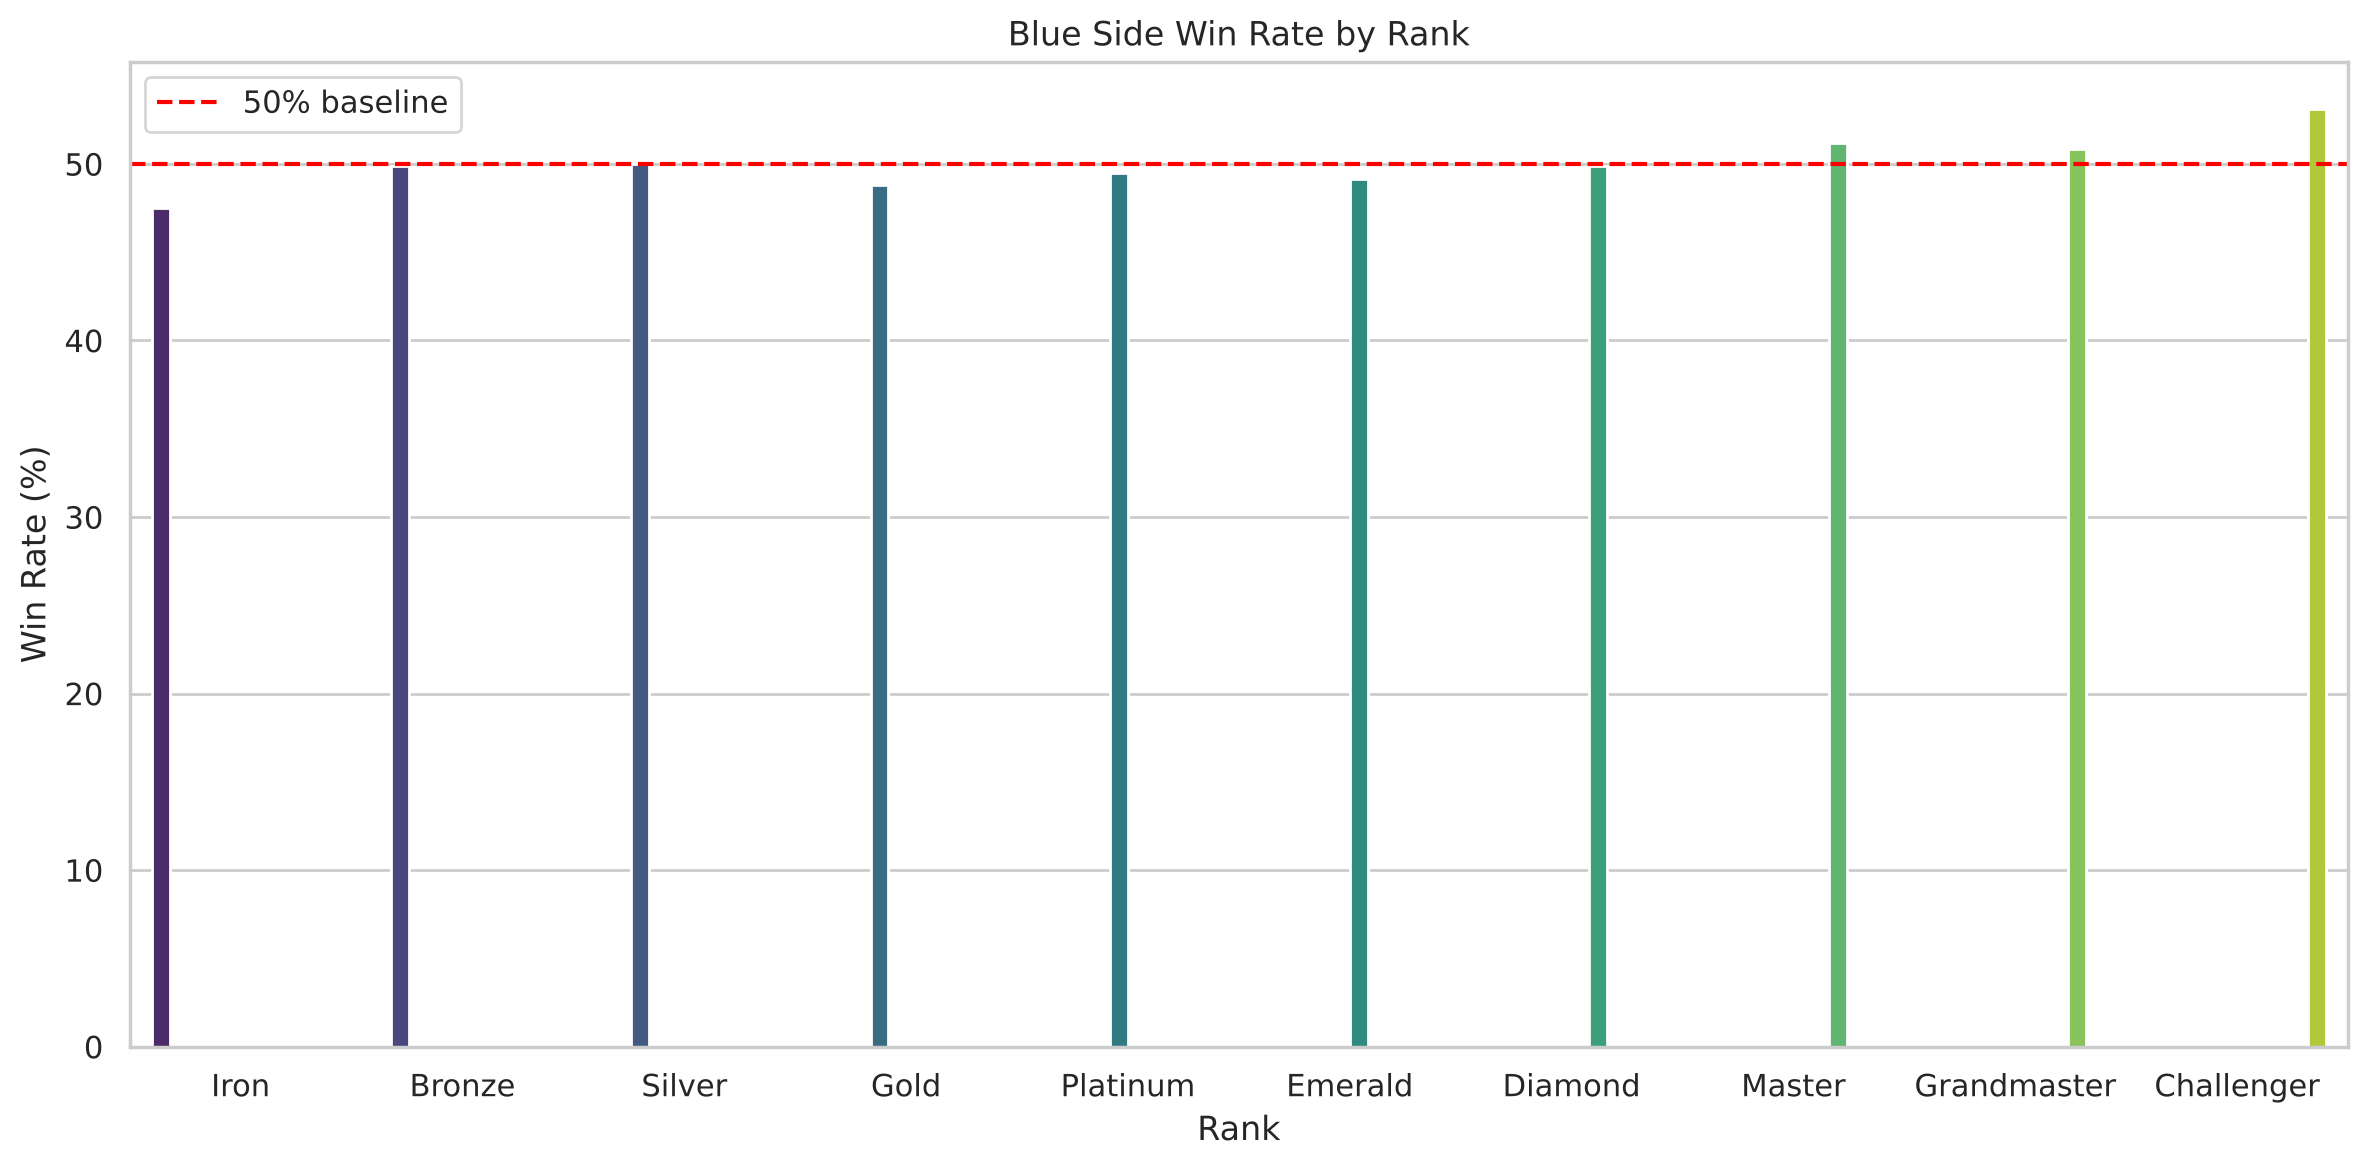

In [4]:
#WR is win rate
win_byRank = lol_data.groupby('RankName', observed=True).agg(
    TotalGames=('BlueWin', 'count'),
    BlueWins=('BlueWin', 'sum')
).reset_index()

win_byRank['WR'] = (win_byRank['BlueWins'] / win_byRank['TotalGames']) * 100

print(win_byRank)

plt.figure(figsize=(12, 6))
sns.barplot(data=win_byRank, x='RankName', y='WR', 
            hue='RankName', palette='viridis', legend=False)
plt.axhline(y=50, color='red', linestyle='--', label='50% baseline')
plt.title('Blue Side Win Rate by Rank')
plt.xlabel('Rank')
plt.ylabel('Win Rate (%)')
plt.legend()
plt.tight_layout()
plt.show()

WR hovers around 50% across all ranks for both blue and red side. For blue side specifically, this ranges from 47.5% in Iron to 53.1% in Challenger. At Master and above, blue has a slight advantage (50.9% - 53.1%), which may suggest that high elo players are able to take more advantage of the draft priority from blue side. At the same time it is important to note that Challenger (the top rank) has a sample size of only 433 games compared to nearly 30,000 Master games (29,890), so it should be interpreted with caution. These are descriptive win rates only; no significance test was run. In conclusion, blue side does not hold a meaningful advantage in almost all ranked tiers.

Games ending before 20 minutes: 9.5%


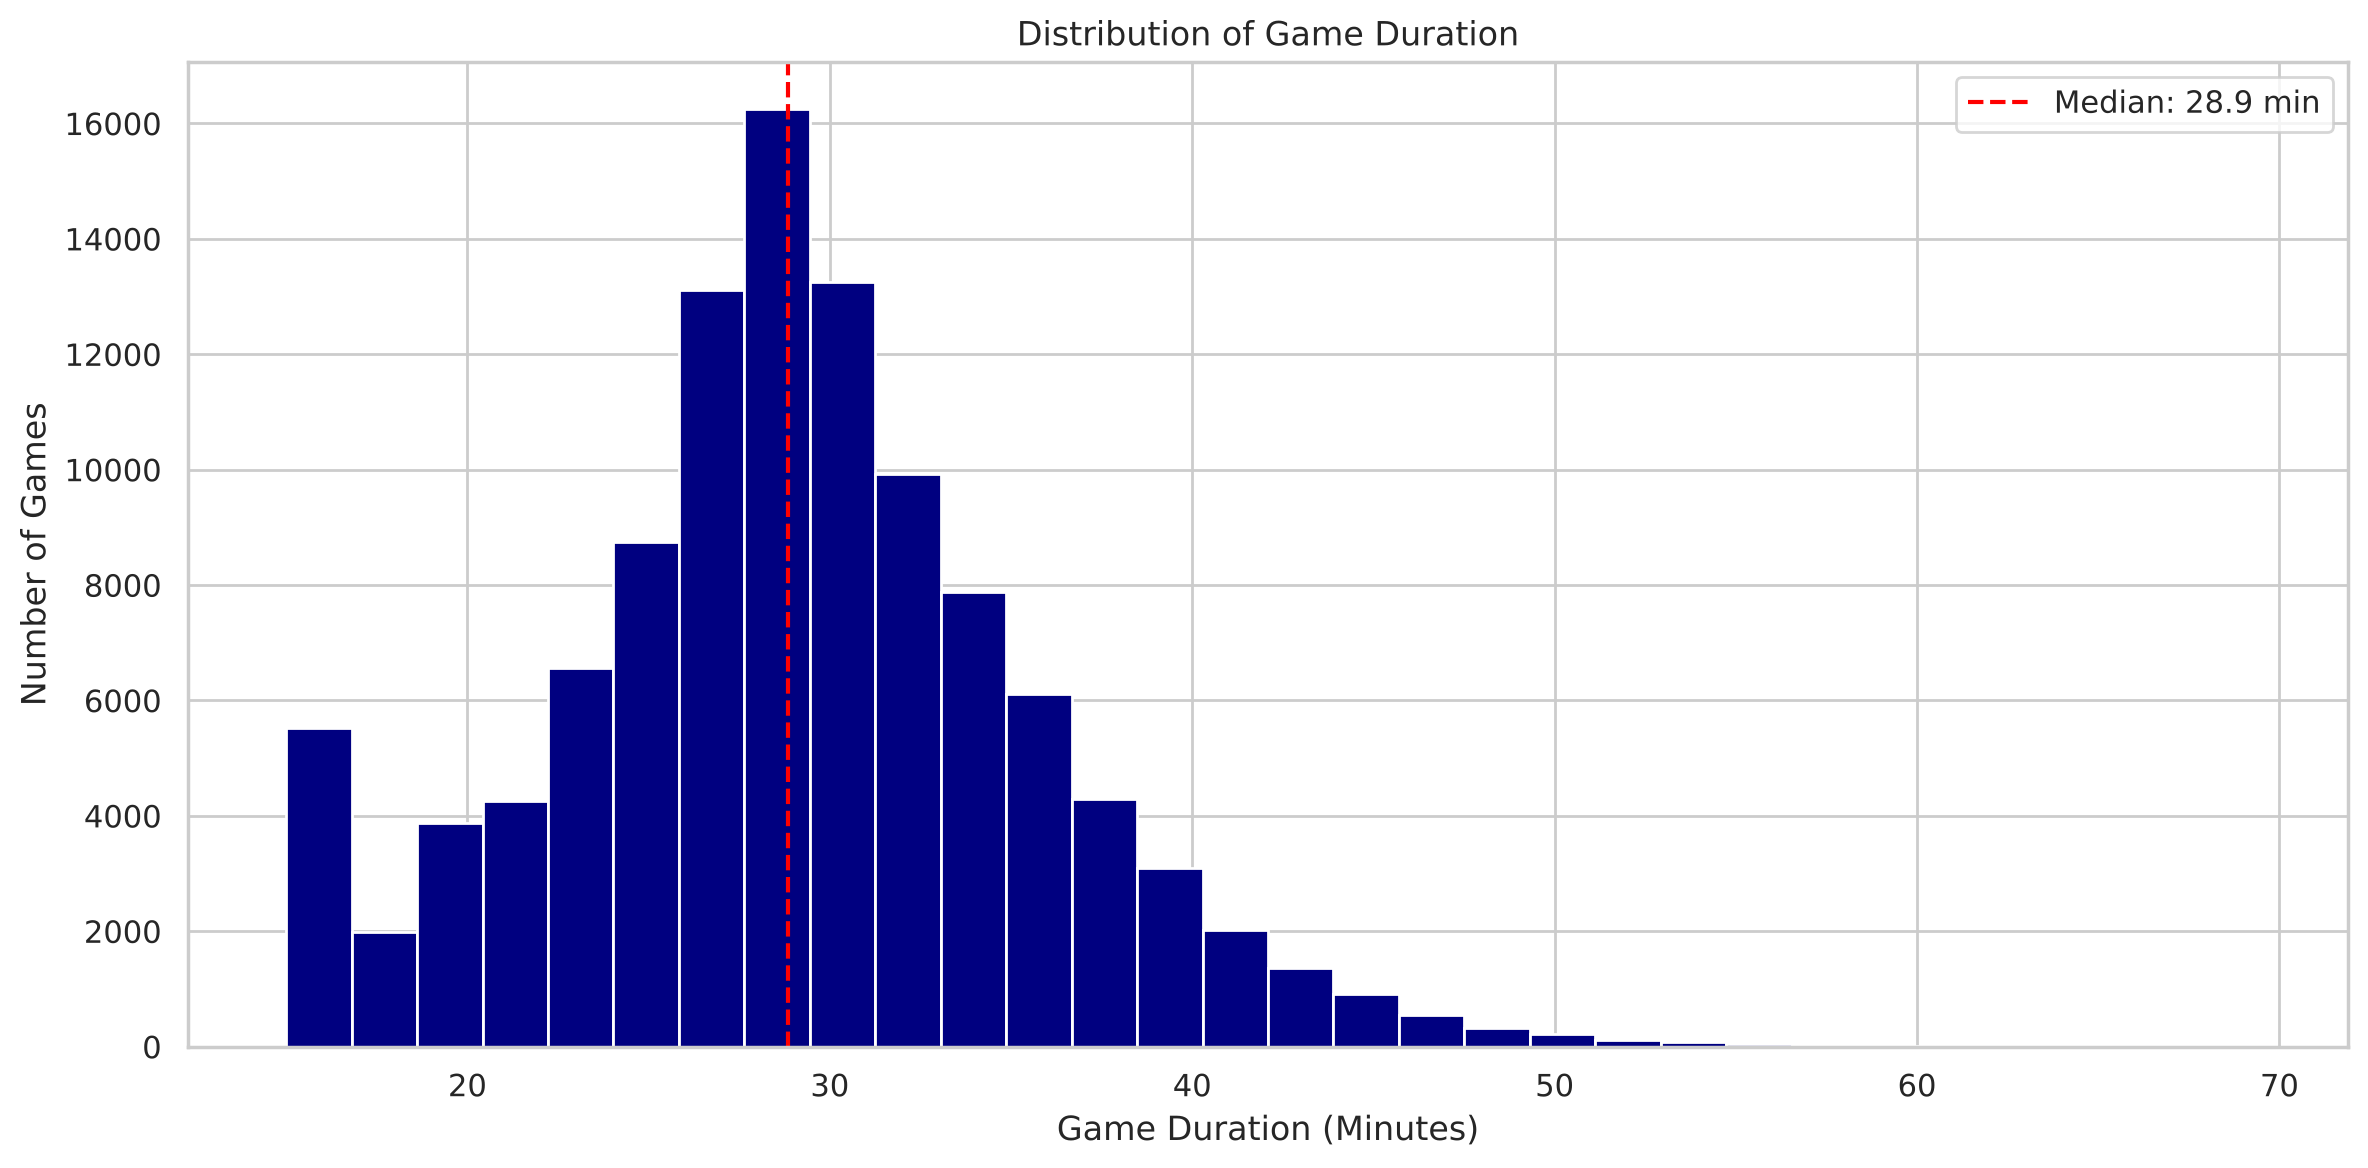

In [5]:
early = len(lol_data[lol_data['GameDuration'] < 20])
earlyPCT = round((early / len(lol_data)) * 100, 1)
print(f"Games ending before 20 minutes: {earlyPCT}%")

plt.figure(figsize=(12, 6))
plt.hist(lol_data['GameDuration'], bins=30, color='navy', edgecolor='white')
plt.axvline(x=lol_data['GameDuration'].median(), 
            color='red', linestyle='--', 
            label=f'Median: {lol_data["GameDuration"].median():.1f} min')
plt.title('Distribution of Game Duration')
plt.xlabel('Game Duration (Minutes)')
plt.ylabel('Number of Games')
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation
Game duration is a right-skewed distribution with a median of approximately 29 minutes. The plot shows a spike in number of games ending between 15-20 minutes. This mostly represents games that end in surrenders as 15 minutes marks the first normal surrender vote window with 20 minutes being the second choice if the votes at 15 minutes failed to go through. the right tail extends to nearly 70 minutes, which should be considered outliers as they represent very rare prolonged matches.

## Objective Differences

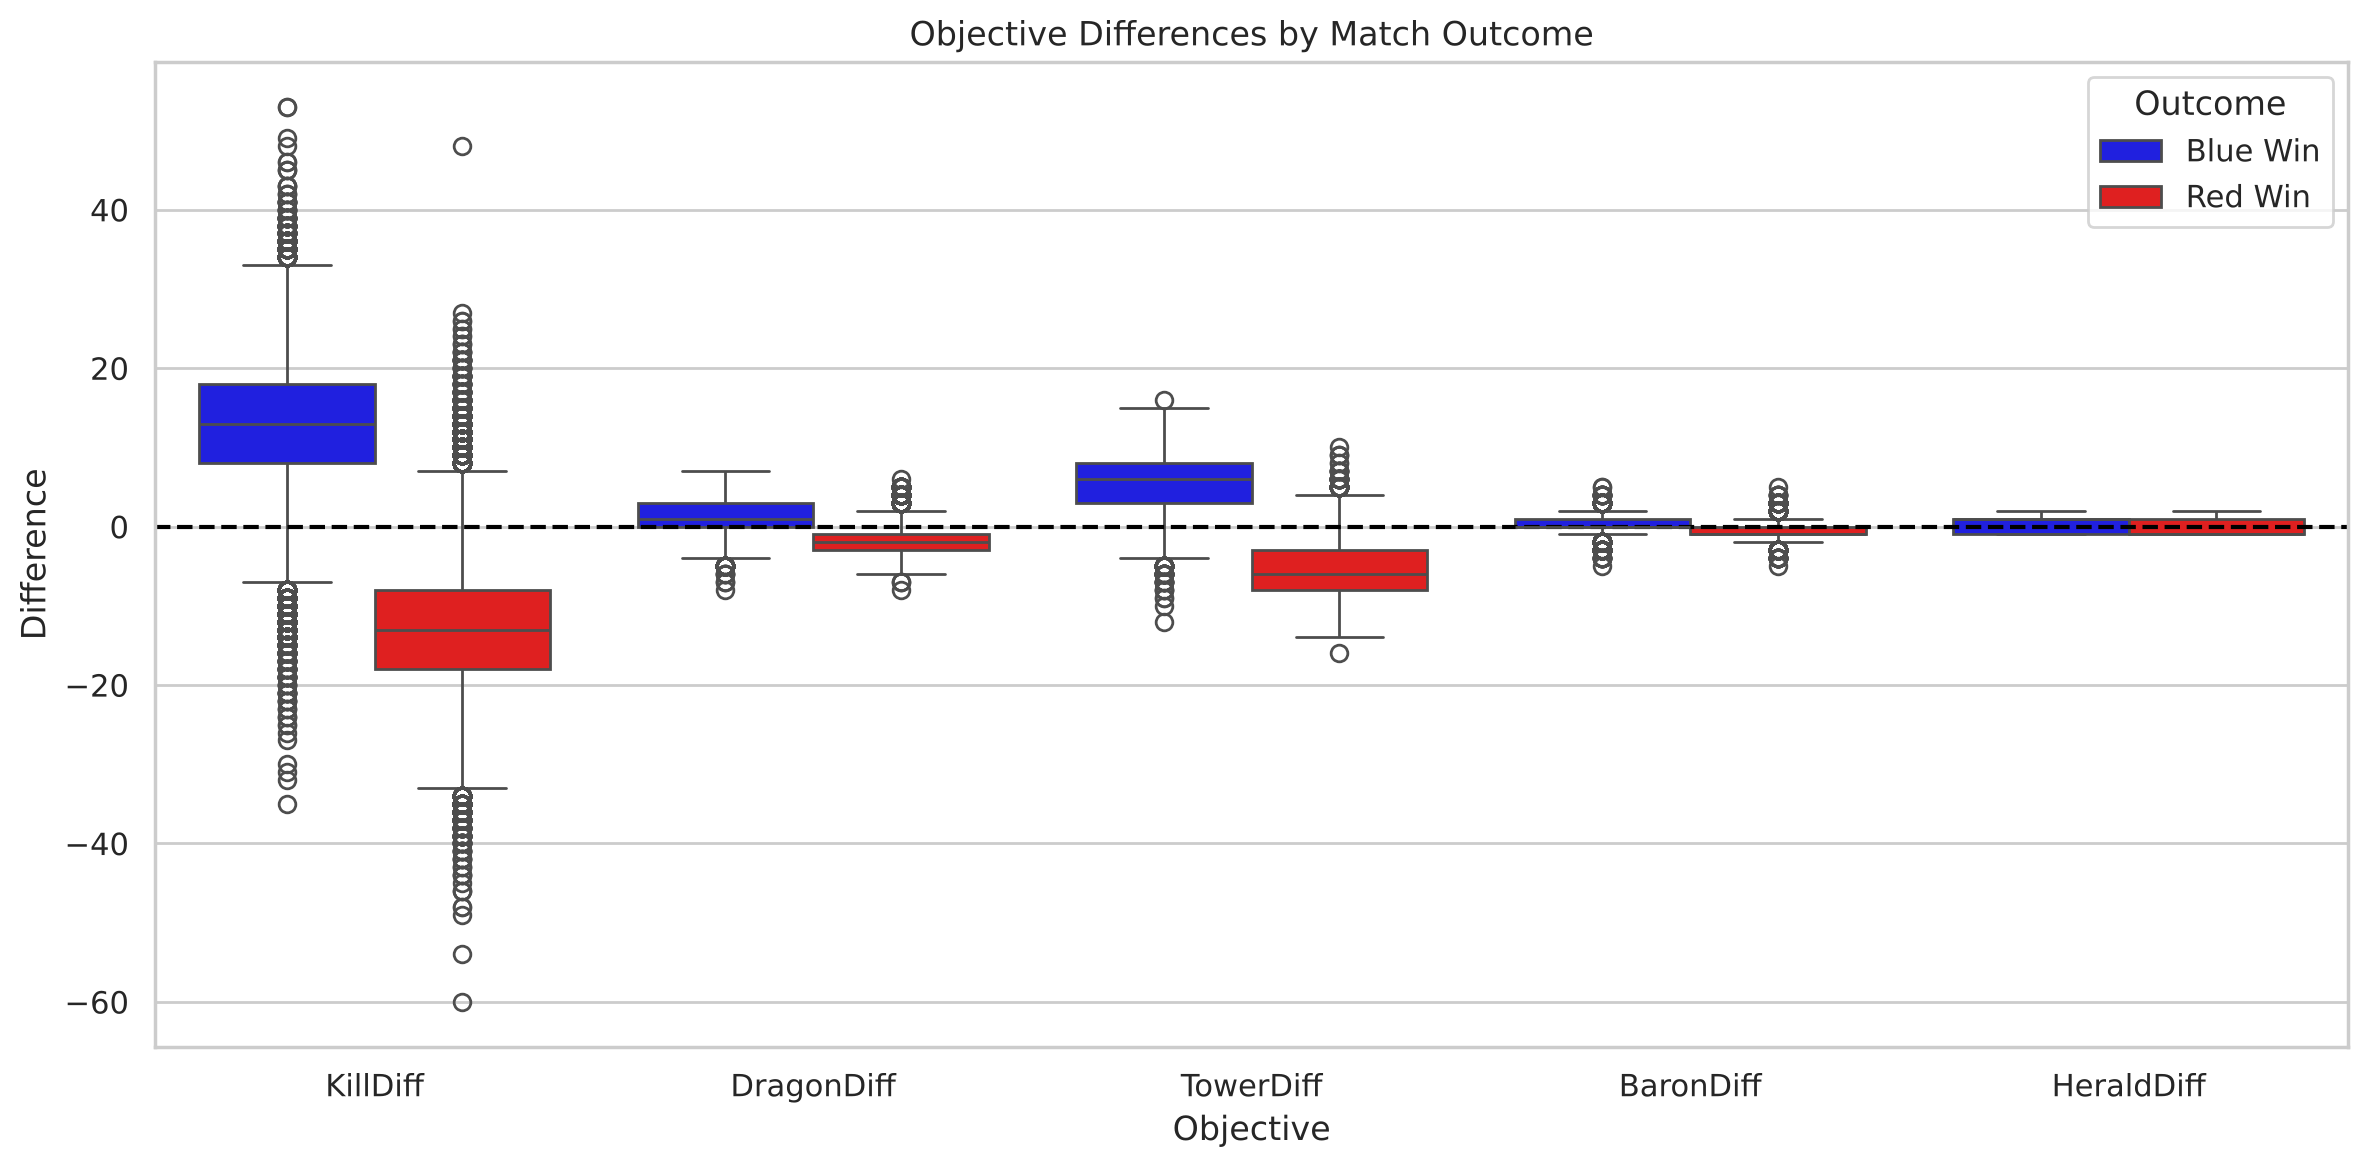

In [6]:
objective_long = lol_data.melt(
    id_vars=['BlueWin'],
    value_vars=['KillDiff', 'DragonDiff', 'TowerDiff', 
                'BaronDiff', 'HeraldDiff'],
    var_name='Objective',
    value_name='Difference'
)

objective_long['Outcome'] = objective_long['BlueWin'].map({
    0: 'Red Win', 
    1: 'Blue Win'
})

plt.figure(figsize=(12, 6))
sns.boxplot(data=objective_long, x='Objective', y='Difference',
            hue='Outcome', palette={'Red Win': 'red', 
                                    'Blue Win': 'blue'})
plt.axhline(y=0, color='black', linestyle='--')
plt.title('Objective Differences by Match Outcome')
plt.xlabel('Objective')
plt.ylabel('Difference')
plt.tight_layout()
plt.show()

### Interpretation
Kill and tower differences are the strongest predictors between winning and losing games. Blue wins are associated with positive differences, and red wins are associated with negative differences. Dragon differences are the next strongest predictors having a moderate, meaningful impact on game outcomes. Lastly, Baron Nashor and Rift Herald differences are weak predictors in game match outcomes.


## Correlation Matrix

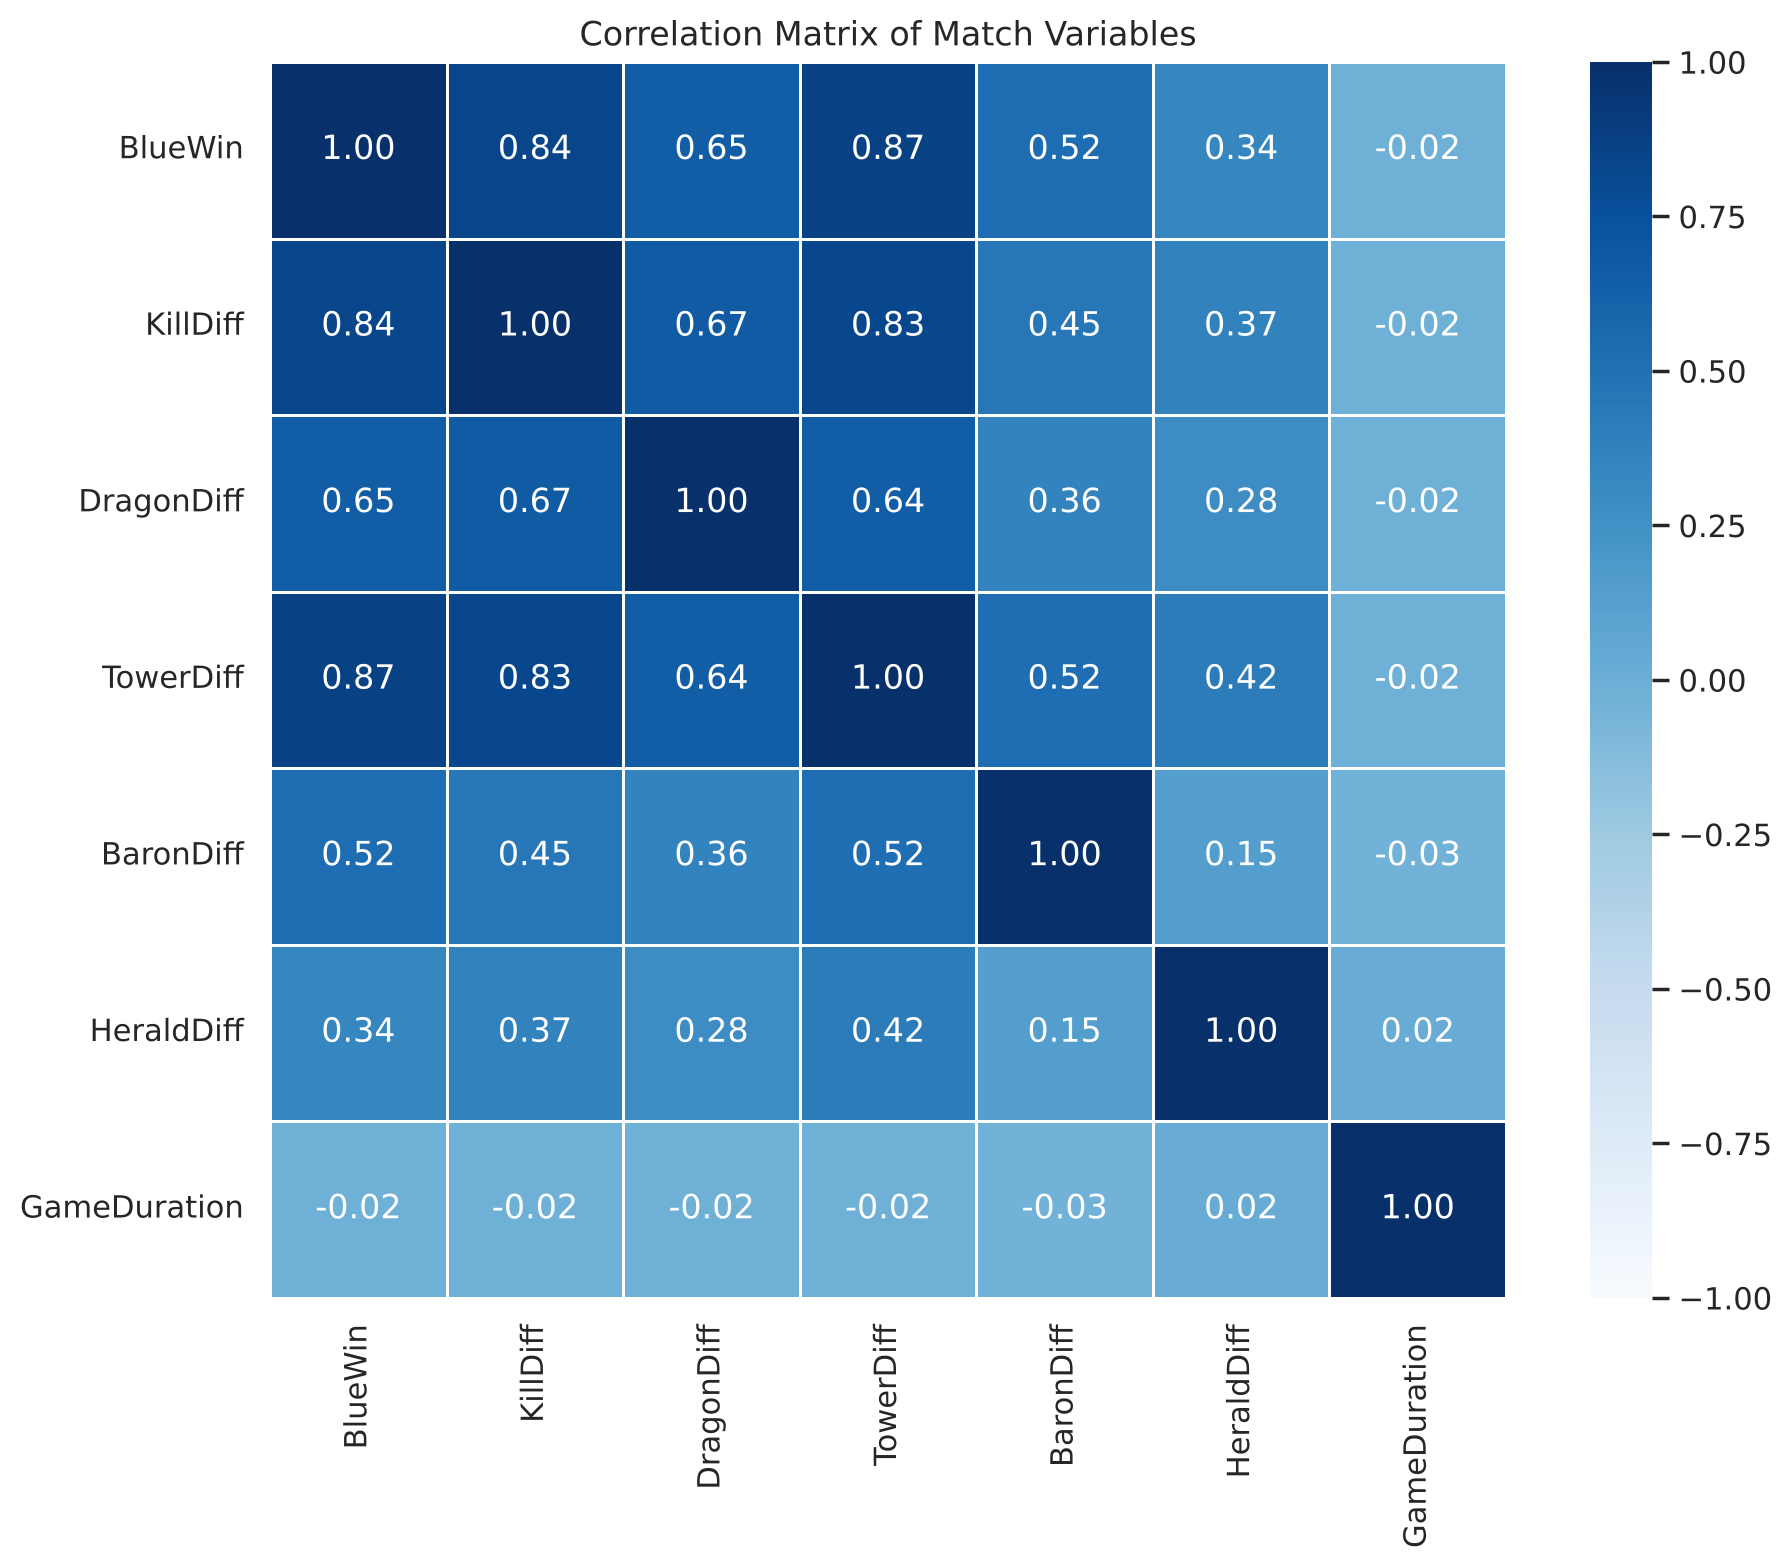

In [7]:
corr_data = lol_data[['BlueWin', 'KillDiff', 'DragonDiff', 'TowerDiff', 'BaronDiff', 
'HeraldDiff', 'GameDuration']]

corr_matrix = corr_data.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix,
            annot=True,
            fmt='.2f',
            cmap='Blues',
            vmin=-1, vmax=1,
            square=True,
            linewidths=0.5)
plt.title('Correlation Matrix of Match Variables')
plt.tight_layout()
plt.show()

### Interpretation
From the correlation matrix and plot, tower difference and kill difference are again the strongest match predictors with a correlation of 0.87 and 0.84 respectively. Dragon, Baron Nashor, and Rift Herald differences also follow what the previous box plot showed with 0.65, 0.52, and 0.34 respectively. Game duration has almost no correlation with match outcomes. 

# Logistic Regression Model
Lol match outcome is basically a binary variable as either a team wins or loses. Using a logistic regression model models the probability of an outcome between 0 and 1, which works nicely with the project question and analysis. 

## Multicollinearity
First we check for multicollinearity which represents an correlation between the variables and tells us if we need to drop any of the variables.

In [8]:
# VIF to check again like project 1
features = ['KillDiff', 'DragonDiff', 'TowerDiff',
            'BaronDiff', 'HeraldDiff', 'GameDuration']

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = add_constant(lol_data[features])

vif_data = pd.DataFrame({
    'Feature': features,
    'VIF': [variance_inflation_factor(X_vif.values, i+1) 
            for i in range(len(features))]
})

print(vif_data.to_string(index=False))

     Feature      VIF
    KillDiff 3.495623
  DragonDiff 1.899846
   TowerDiff 3.739210
   BaronDiff 1.381746
  HeraldDiff 1.224580
GameDuration 1.001930


### Interpretation

Before running the model, VIF (Variance Inflation Factor) scores were checked for multicollinearity. The correlation matrix suggested that KillDiff and TowerDiff move together, and the VIFs reflect that: they are the highest, at about 3.5 and 3.7, but still below the common rule-of-thumb threshold of 5. The other features are between 1.0 and 1.9. All six variables were kept.

A note on method: the R version of this project used `car::vif` on the fitted logistic model, which is based on the covariance of the estimated coefficients and reported values below 1.2 for every variable. The calculation above uses the design matrix (statsmodels), which is a different measure, so the numbers differ. The coefficient-covariance version is recomputed in Python in the cell below the model and also gives values between 1.0 and 1.2. Both lead to the same conclusion.

## Model Results

Accuracy: 97.63%

Classification Report:
              precision    recall  f1-score   support

     Red Win       0.98      0.97      0.98     10987
    Blue Win       0.97      0.98      0.98     11118

    accuracy                           0.98     22105
   macro avg       0.98      0.98      0.98     22105
weighted avg       0.98      0.98      0.98     22105



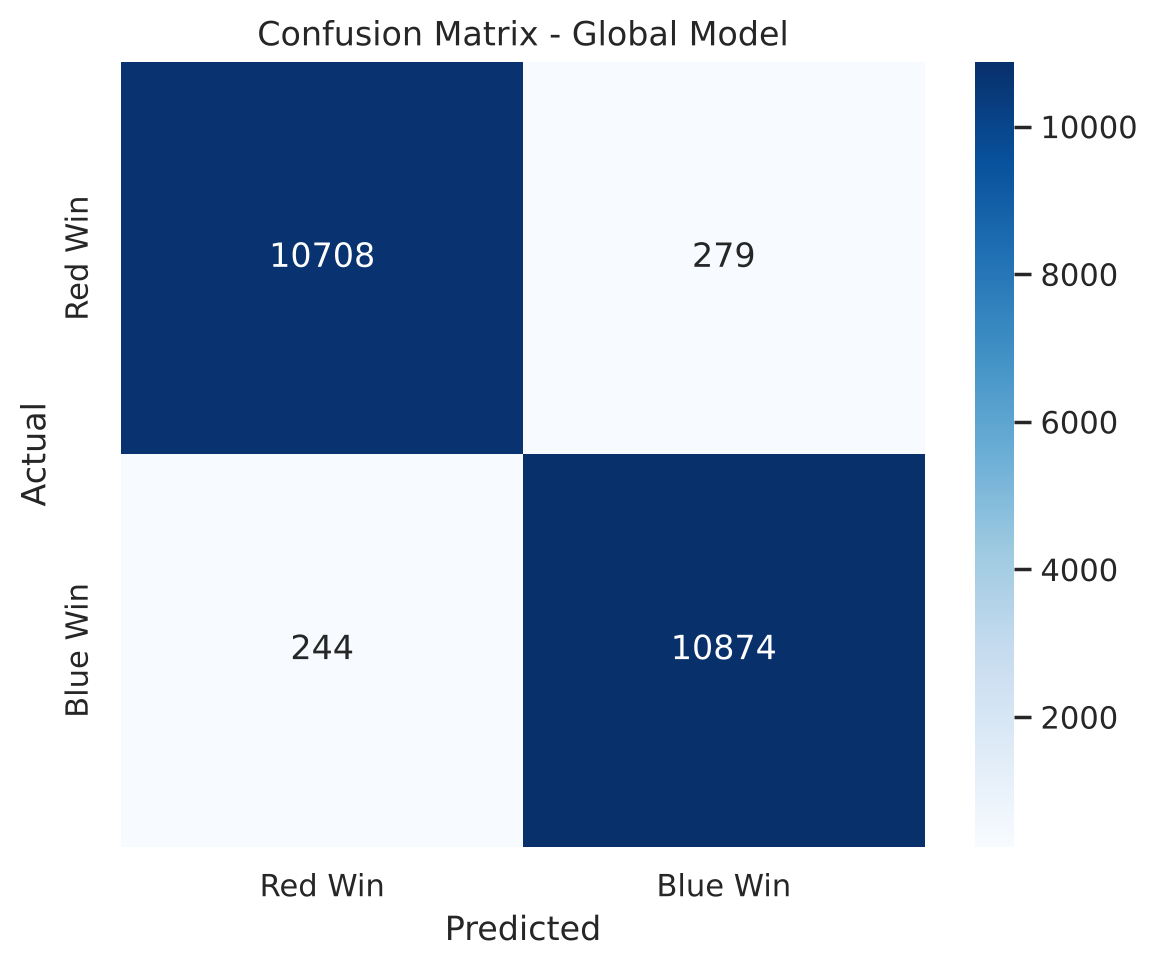


Model Coefficients:
        Feature  Coefficient
2     TowerDiff     0.819307
3     BaronDiff     0.213441
0      KillDiff     0.187470
1    DragonDiff     0.161888
5  GameDuration    -0.001584
4    HeraldDiff    -0.368088


In [9]:
features = ['KillDiff', 'DragonDiff', 'TowerDiff', 
'BaronDiff', 'HeraldDiff', 'GameDuration']

X = lol_data[features]
y = lol_data['BlueWin']

#training and testing data (80/20 split)
xTrain, xTest, yTrain, yTest = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LogisticRegression(max_iter=1000)
model.fit(xTrain, yTrain)
yPred = model.predict(xTest)

accuracy = accuracy_score(yTest, yPred) * 100
print(f"Accuracy: {round(accuracy, 2)}%")
print("\nClassification Report:")
print(classification_report(yTest, yPred, 
target_names=['Red Win', 'Blue Win']))

# Confusion matrix
cm = confusion_matrix(yTest, yPred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
xticklabels=['Red Win', 'Blue Win'],
yticklabels=['Red Win', 'Blue Win'])
plt.title('Confusion Matrix - Global Model')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Coefficients
coef_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_[0]
}).sort_values('Coefficient', ascending=False)

print("\nModel Coefficients:")
print(coef_df)

In [10]:
# Unpenalized logistic regression on all games (statsmodels) for coefficient inference.
# scikit-learn above is used for held-out prediction; statsmodels gives standard errors and p-values.
X_all = sm.add_constant(lol_data[features])
logit_res = sm.Logit(lol_data['BlueWin'], X_all).fit(disp=0)
print(logit_res.summary2().tables[1].round(4))

in_sample_pred = (logit_res.predict(X_all) > 0.5).astype(int)
misclassified = int((in_sample_pred != lol_data['BlueWin']).sum())
print(f"\nIn-sample accuracy (all {len(lol_data):,} games): "
      f"{(1 - misclassified / len(lol_data)) * 100:.2f}% ({misclassified:,} misclassified)")

# VIF from the coefficient covariance matrix (the approach used by R's car::vif)
cov = logit_res.cov_params().iloc[1:, 1:]
sd = np.sqrt(np.diag(cov))
corr = cov.values / np.outer(sd, sd)
print("\nCoefficient-covariance VIF:")
print(pd.Series(np.diag(np.linalg.inv(corr)), index=features).round(3).to_string())

               Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
const         0.0528    0.0835   0.6330  0.5267 -0.1108  0.2164
KillDiff      0.1899    0.0028  66.7742  0.0000  0.1844  0.1955
DragonDiff    0.1501    0.0112  13.3868  0.0000  0.1281  0.1721
TowerDiff     0.8118    0.0097  83.5274  0.0000  0.7928  0.8309
BaronDiff     0.2127    0.0211  10.1010  0.0000  0.1715  0.2540
HeraldDiff   -0.3648    0.0237 -15.4174  0.0000 -0.4112 -0.3184
GameDuration -0.0009    0.0025  -0.3437  0.7311 -0.0058  0.0040

In-sample accuracy (all 110,521 games): 97.60% (2,652 misclassified)

Coefficient-covariance VIF:
KillDiff        1.110
DragonDiff      1.069
TowerDiff       1.080
BaronDiff       1.021
HeraldDiff      1.067
GameDuration    1.001


### Interpretation

Coefficient significance comes from the unpenalized statsmodels fit above. scikit-learn's `LogisticRegression` applies mild L2 regularization by default and does not report p-values; its coefficients (printed earlier) are within about 0.01 of these.

Five of the six predictors are statistically significant. Only game duration is not (p = 0.731), so it adds no reliable information. Tower difference has the largest coefficient (0.812). Kill difference (0.19), Baron Nashor difference (0.21) and Dragon difference (0.15) are also positively associated with winning. Rift Herald difference has a negative association (-0.36), which can be explained by losing teams prioritizing Rift Herald in an attempt to catch up, while winning teams prioritize towers and dragons. The intercept is not statistically significant (p = 0.527), consistent with no meaningful blue side advantage once objectives are accounted for.

Coefficients are per unit and the predictors are on different scales (kill differences span roughly +/-60 while tower differences are bounded by the number of towers), so coefficient size is a rough guide to importance, not a like-for-like ranking.

In [11]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(yTest, yPred)
TN = cm[0][0]
FP = cm[0][1]
FN = cm[1][0]
TP = cm[1][1]

# sensitivity and specificity
sensitivity = (TP / (TP + FN)) * 100
specificity = (TN / (TN + FP)) * 100

print(f"Accuracy: {round(accuracy, 2)}%")
print(f"Sensitivity: {round(sensitivity, 2)}%")
print(f"Specificity: {round(specificity, 2)}%")

Accuracy: 97.63%
Sensitivity: 97.81%
Specificity: 97.46%


### Interpretation

On the held-out 20% test set (22,105 games) the model has an overall accuracy of 97.63%, with a sensitivity of 97.81% and a specificity of 97.46%. Blue and Red wins are predicted about equally well. Fit on all 110,521 games, the same model form scores 97.60% (2,652 misclassified), nearly identical to the held-out figure, so there is no sign of overfitting.

This accuracy is high because the predictors are end-of-game statistics that largely determine the outcome. It is not a forecast of a game in progress; see Limitations and Future Work.

# Objective Importance Across Rank

We now have an idea of the importance of objectives across all matches and how impactful each one is in correlation to winning games. Now, we analyze the data across different ranks in order to determine if the objective importance cahnges through each rank. Here we create 10 models, one for each rank, and then train them on only their rank data.

In [12]:
rank_results = []

for rank in rank_order:
    # Filter by rank
    rank_data = lol_data[lol_data['RankName'] == rank]

    if len(rank_data) < 200:
        continue
    
    xRank = rank_data[features]
    yRank = rank_data['BlueWin']
    
    # Train/test
    xTrain_r, xTest_r, yTrain_r, yTest_r = train_test_split(
        xRank, yRank, test_size=0.2, random_state=42
    )
    
    rank_model = LogisticRegression(max_iter=1000)
    rank_model.fit(xTrain_r, yTrain_r)
    
    yPred_r = rank_model.predict(xTest_r)
    acc = accuracy_score(yTest_r, yPred_r) * 100
    
    rank_results.append({
        'Rank': rank,
        'Accuracy': round(acc, 2),
        'TowerDiff': rank_model.coef_[0][2],
        'KillDiff': rank_model.coef_[0][0],
        'DragonDiff': rank_model.coef_[0][1],
        'BaronDiff': rank_model.coef_[0][3],
        'HeraldDiff': rank_model.coef_[0][4],
        'GameDuration': rank_model.coef_[0][5]
    })

rank_results_df = pd.DataFrame(rank_results)
print(rank_results_df.to_string(index=False))

       Rank  Accuracy  TowerDiff  KillDiff  DragonDiff  BaronDiff  HeraldDiff  GameDuration
       Iron     95.56   0.721792  0.184238    0.232135  -0.038554   -0.249528     -0.015751
     Bronze     95.94   0.749703  0.170330    0.294402   0.552119   -0.227488      0.027883
     Silver     97.08   0.787467  0.169930    0.171222   0.261721   -0.332355      0.003538
       Gold     97.10   0.819091  0.193283    0.194270   0.245007   -0.239253      0.004416
   Platinum     97.29   0.769420  0.177239    0.155352   0.229878   -0.413479     -0.009952
    Emerald     96.94   0.790480  0.190137    0.159930   0.331091   -0.383359      0.009654
    Diamond     97.46   0.814049  0.197918    0.116198   0.136619   -0.318984     -0.009593
     Master     97.83   0.903880  0.209298    0.135248   0.233257   -0.414119     -0.008732
Grandmaster     98.02   0.920676  0.177440    0.055951   0.405797   -0.546978     -0.007752
 Challenger     95.40   1.527858  0.550143   -0.051567  -0.032233   -1.378952   

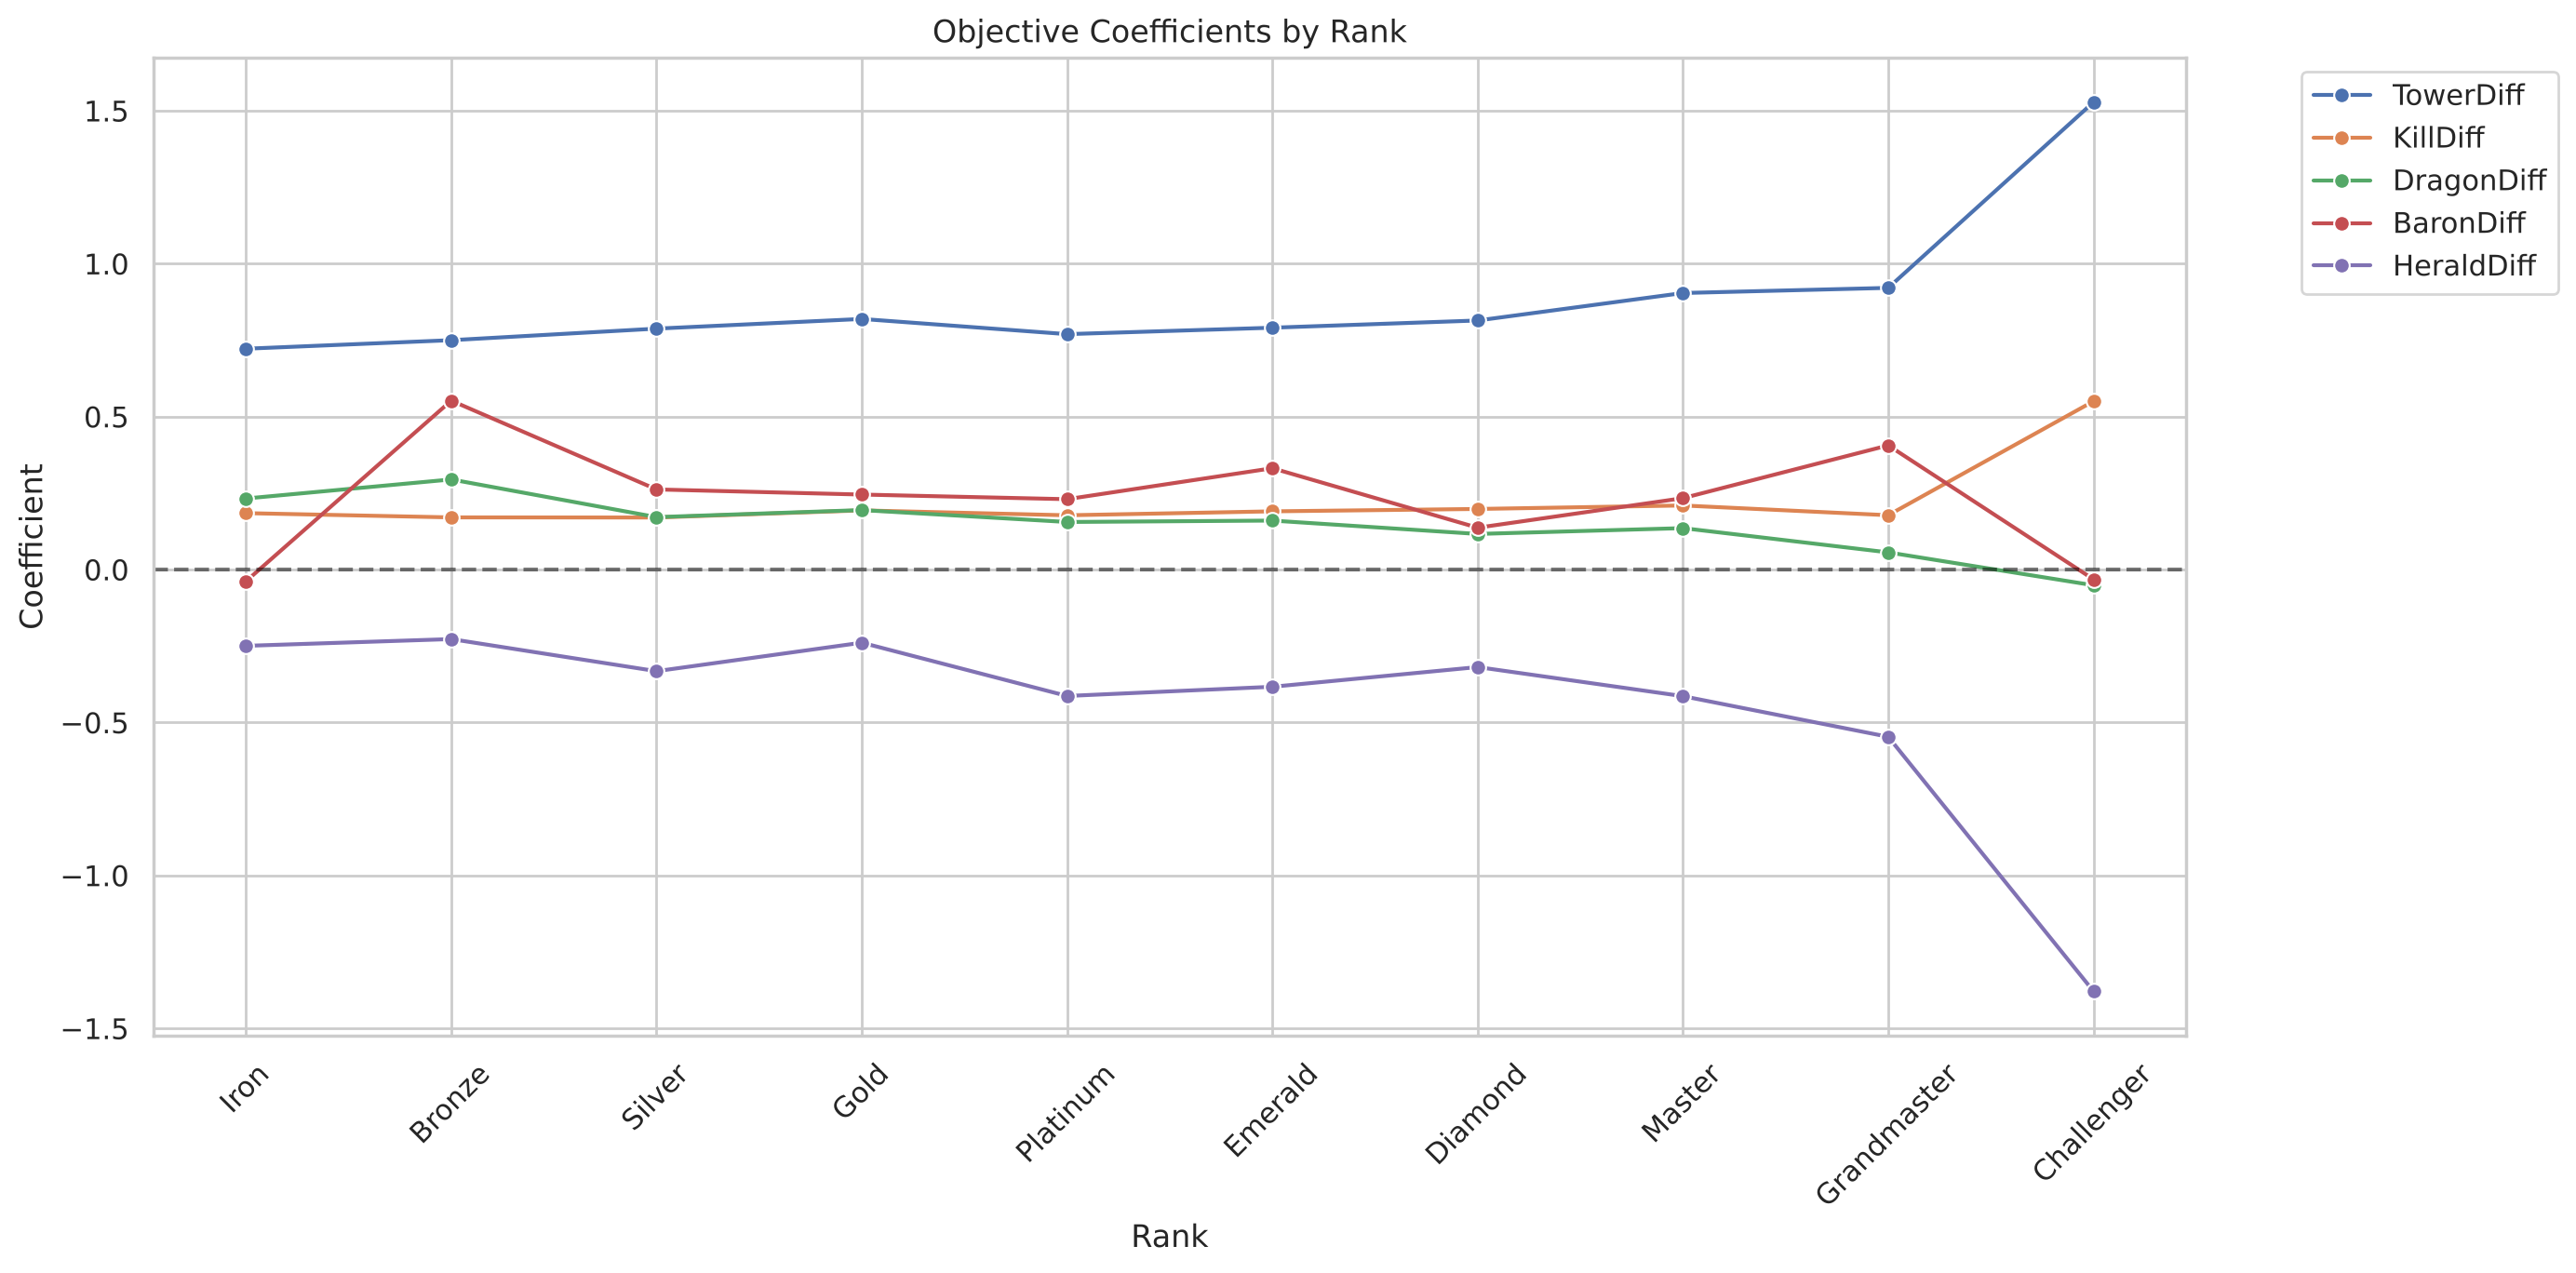

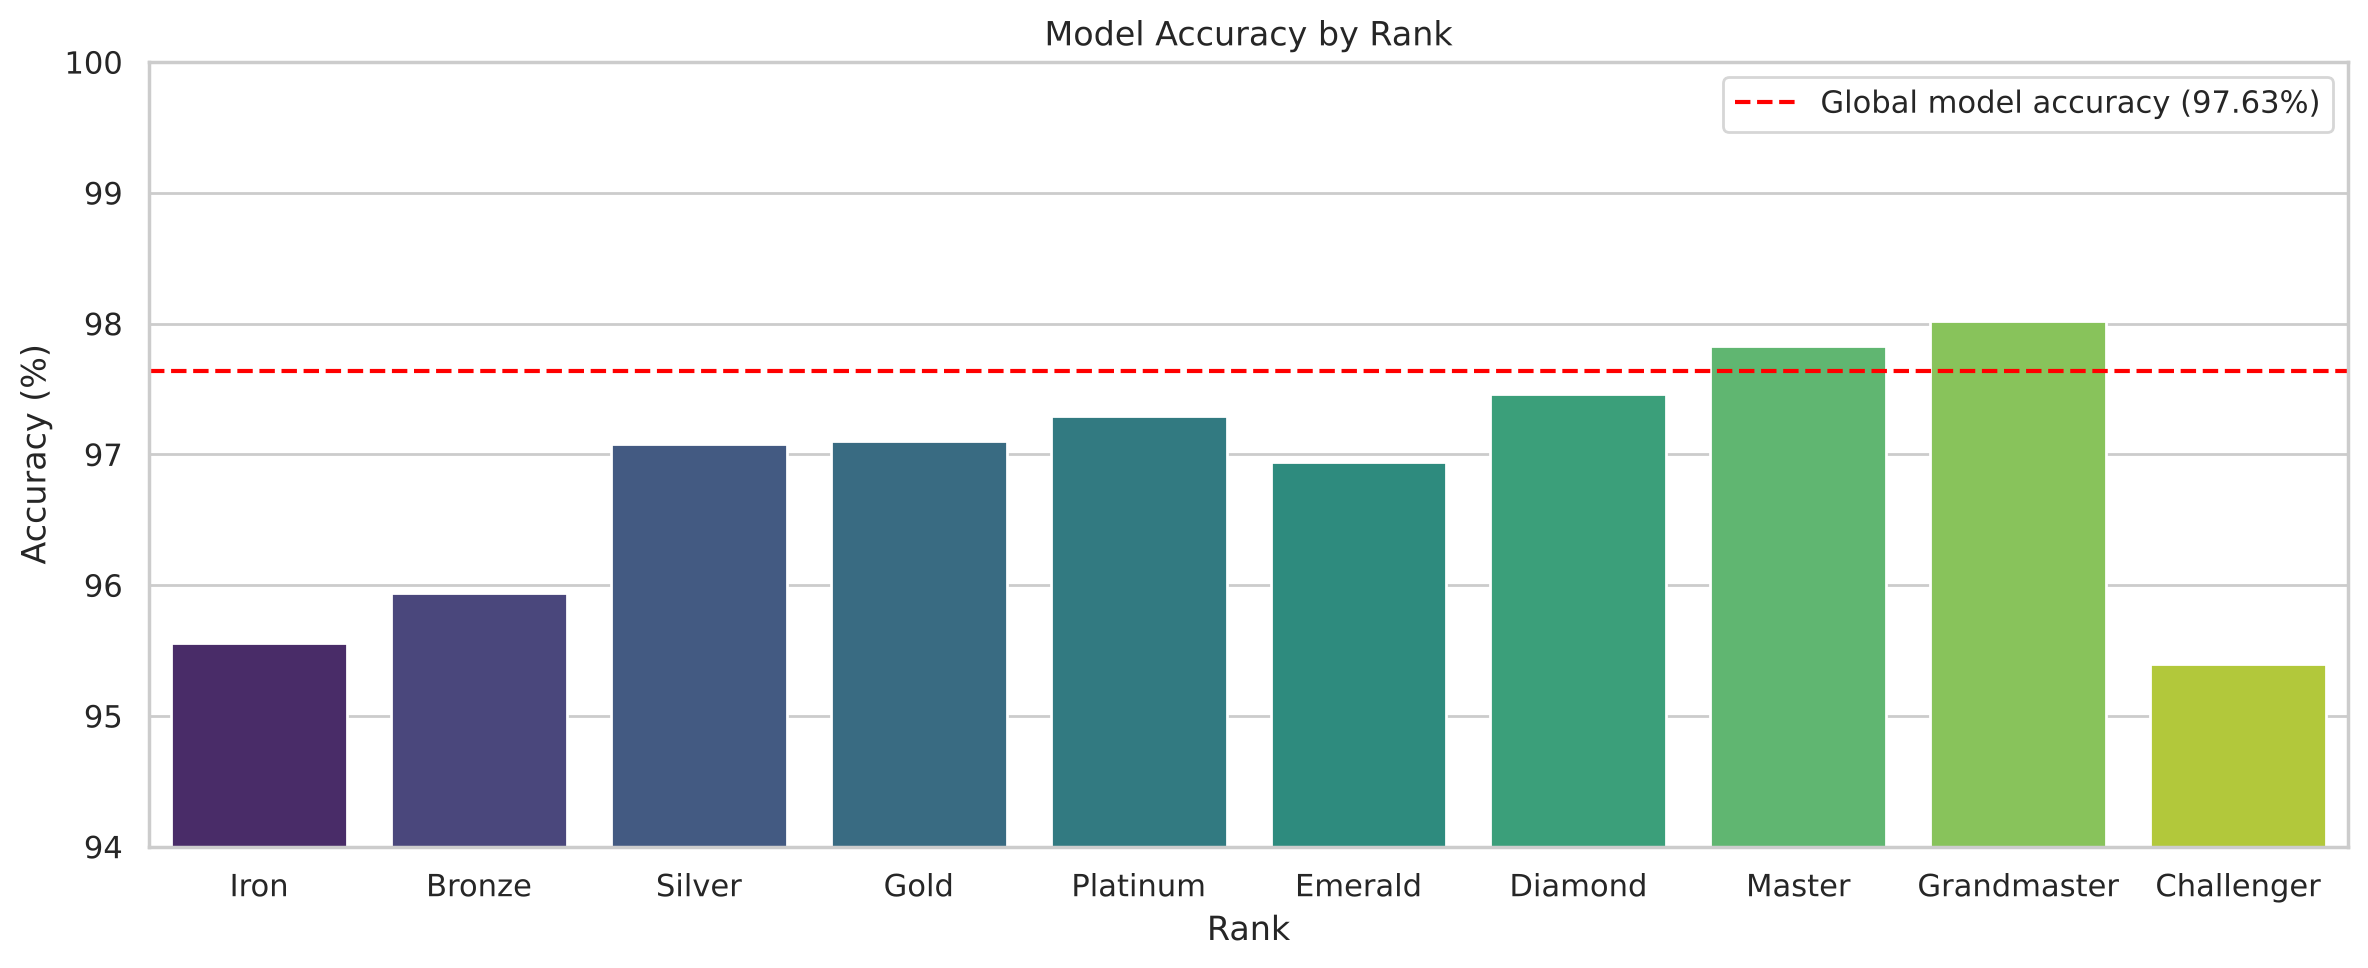

In [13]:
#coefficients by rank
coefCols = ['TowerDiff', 'KillDiff', 'DragonDiff', 
'BaronDiff', 'HeraldDiff']

rank_coef_long = rank_results_df.melt(
    id_vars='Rank',
    value_vars=coefCols,
    var_name='Objective',
    value_name='Coefficient'
)

plt.figure(figsize=(14, 7))
sns.lineplot(data=rank_coef_long, x='Rank', y='Coefficient',
hue='Objective', marker='o')
plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)
plt.title('Objective Coefficients by Rank')
plt.xlabel('Rank')
plt.ylabel('Coefficient')
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
sns.barplot(data=rank_results_df, x='Rank', y='Accuracy',
            hue='Rank', palette='viridis', legend=False)
plt.axhline(y=accuracy, color='red', linestyle='--',
            label=f'Global model accuracy ({accuracy:.2f}%)')
plt.title('Model Accuracy by Rank')
plt.xlabel('Rank')
plt.ylabel('Accuracy (%)')
plt.ylim(94, 100)
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

The line plot shows how objective coefficients shift across ranks. Tower difference rises the most, from 0.72 in Iron to 1.53 in Challenger, suggesting that higher-ranked games are decided more by towers. Kill difference is mostly stable (about 0.17 to 0.21), then jumps in Challenger to 0.55 (Iron: 0.18). Dragon difference is also fairly stable, then dips slightly below zero in Challenger. Herald difference is negative at every rank and becomes more negative toward the top, from -0.25 in Iron to -1.38 in Challenger, probably because losing teams prioritize Herald in an attempt to catch up. Baron difference peaks in Bronze (0.55) and Grandmaster (0.41) and is near zero in Iron and Challenger. There is no steady trend, so it is hard to read a pattern into it.

Caution: Challenger has only 433 games (about 346 for training and 87 for testing), so its large coefficients and its accuracy are noisy.

The bar chart compares each rank's accuracy with the global model's. Accuracy ranges from about 95.4% to 98.0%, so the model performs similarly at every rank. Challenger is the lowest, likely because of its small sample.

In [14]:
#duration segments
lol_data['GameSegment'] = pd.cut(
    lol_data['GameDuration'],
    bins=[15, 25, 35, 70],
    labels=['Early (15-25 min)', 'Mid (25-35 min)', 'Late (35+ min)'],
    include_lowest=True  # keep games of exactly 15.0 minutes
)

# games in each segment
print("Games per segment:")
print(lol_data['GameSegment'].value_counts().sort_index())

Games per segment:
GameSegment
Early (15-25 min)    26763
Mid (25-35 min)      65082
Late (35+ min)       18676
Name: count, dtype: int64


## Objective Importance in Relation to Game Length

Finally this project looks at whether the game duration has any impact on the importance of objectives. Below, the games are segmented into three differnt types based on their types: Early, Mid, and Late. More logistic regresssion models were built for the segments.

In [15]:
segment_results = []
segment_order = ['Early (15-25 min)', 'Mid (25-35 min)', 'Late (35+ min)']

for segment in segment_order:
    # Filter
    seg_data = lol_data[lol_data['GameSegment'] == segment]
    
    X_seg = seg_data[features]
    y_seg = seg_data['BlueWin']
    
    # Train/test split
    xTrain_s, xTest_s, yTrain_s, yTest_s = train_test_split(
        X_seg, y_seg, test_size=0.2, random_state=42
    )
    
    seg_model = LogisticRegression(max_iter=1000)
    seg_model.fit(xTrain_s, yTrain_s)

    yPred_s = seg_model.predict(xTest_s)
    acc = accuracy_score(yTest_s, yPred_s) * 100
    
    segment_results.append({
        'Segment': segment,
        'Games': len(seg_data),
        'Accuracy': round(acc, 2),
        'TowerDiff': seg_model.coef_[0][2],
        'KillDiff': seg_model.coef_[0][0],
        'DragonDiff': seg_model.coef_[0][1],
        'BaronDiff': seg_model.coef_[0][3],
        'HeraldDiff': seg_model.coef_[0][4],
        'GameDuration': seg_model.coef_[0][5]
    })

seg_results_df = pd.DataFrame(segment_results)
print(seg_results_df.to_string(index=False))

          Segment  Games  Accuracy  TowerDiff  KillDiff  DragonDiff  BaronDiff  HeraldDiff  GameDuration
Early (15-25 min)  26763     99.66   0.968527  0.452993    0.379167   0.000179    0.114216      0.002934
  Mid (25-35 min)  65082     98.79   0.962610  0.186867    0.079273   0.837888   -0.597172      0.003061
   Late (35+ min)  18676     90.85   0.596398  0.123322    0.153003   0.102770   -0.308801     -0.007167


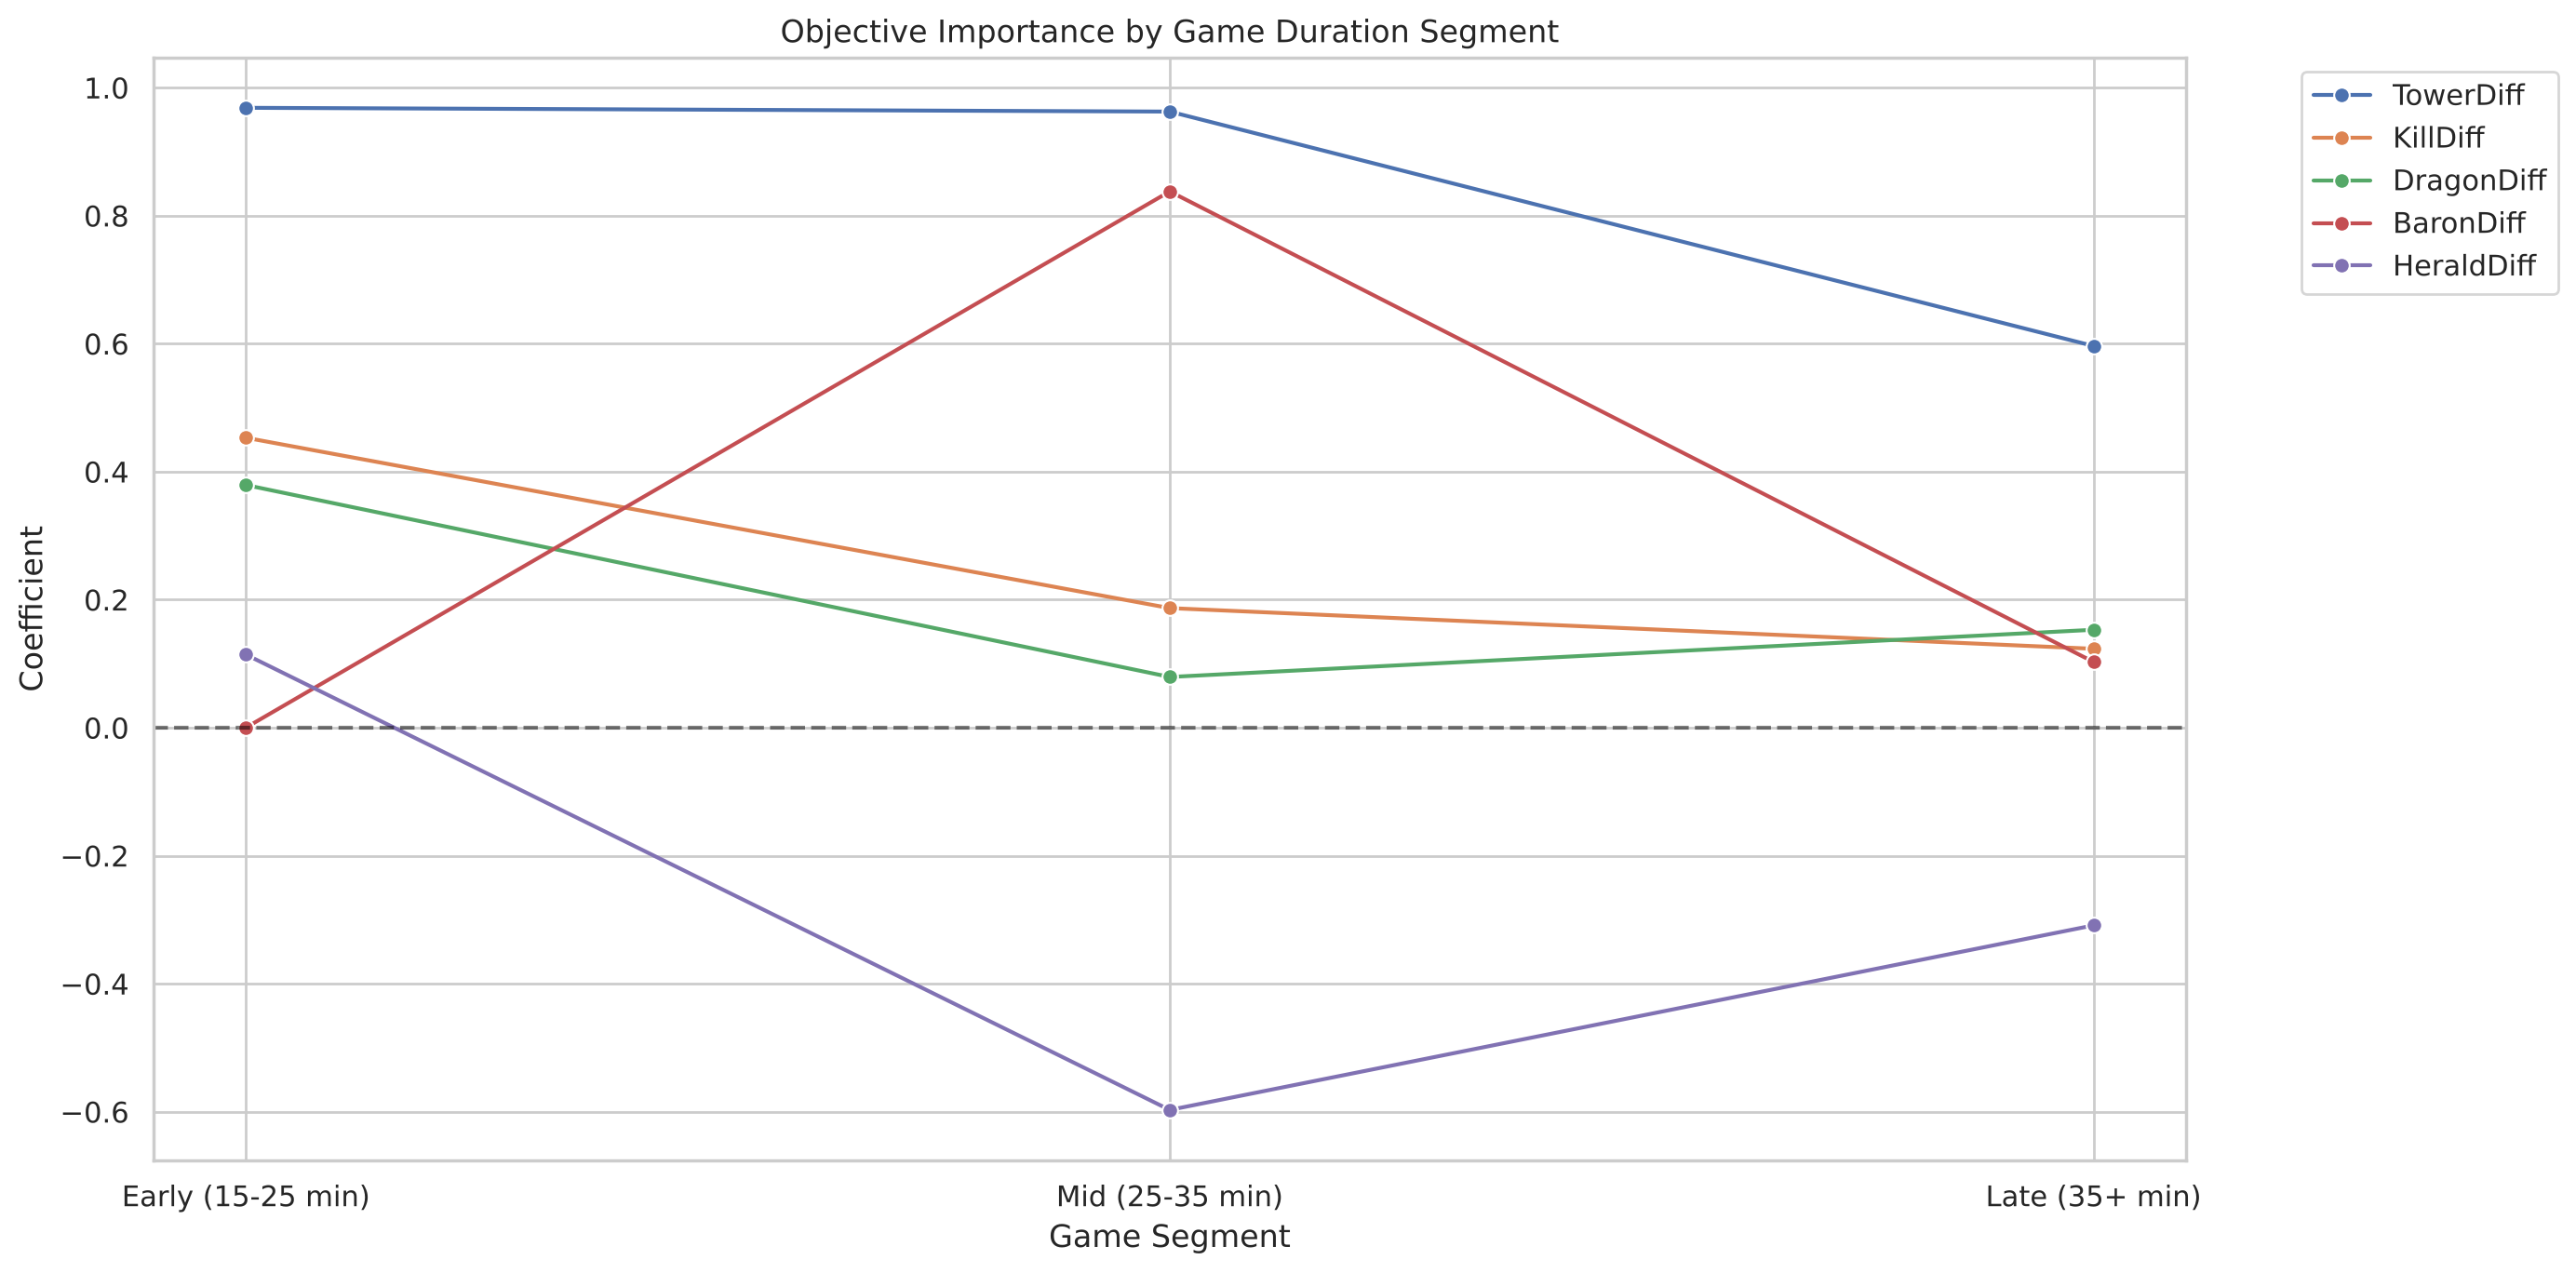

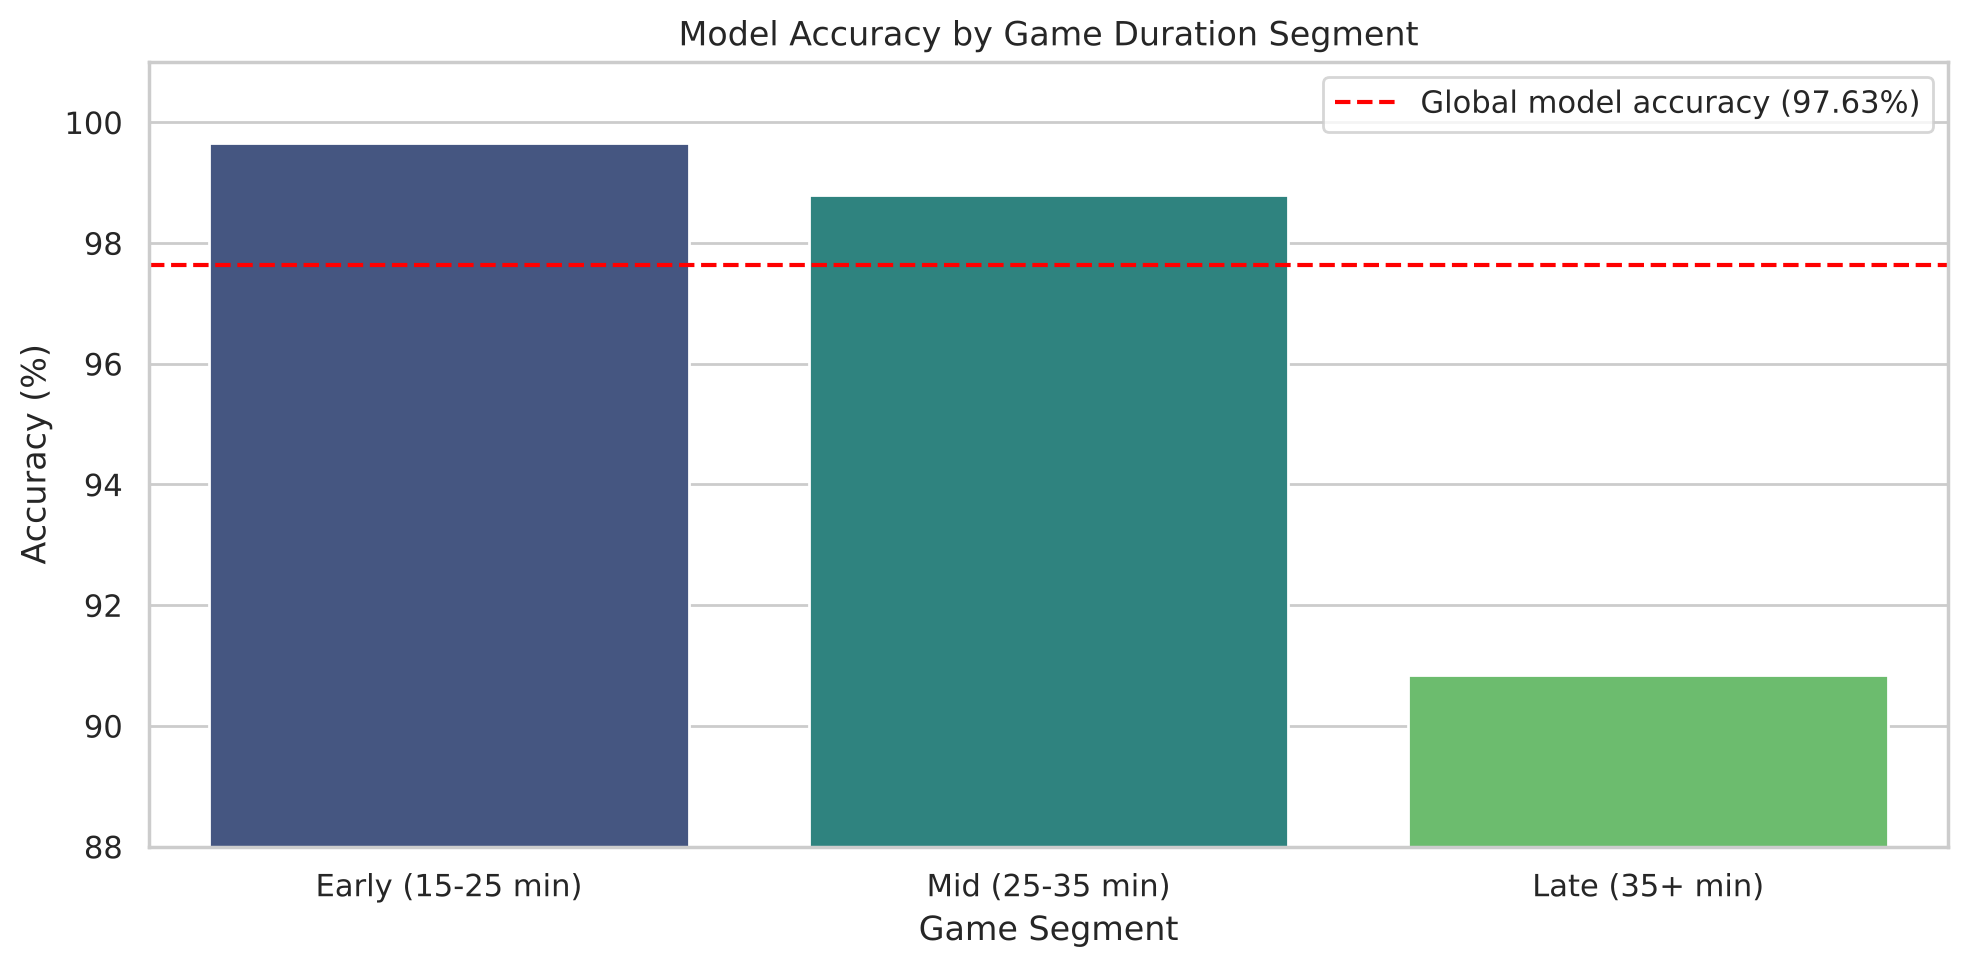

In [16]:
coefCols = ['TowerDiff', 'KillDiff', 'DragonDiff', 
'BaronDiff', 'HeraldDiff']

seg_coef_long = seg_results_df.melt(
    id_vars='Segment',
    value_vars=coefCols,
    var_name='Objective',
    value_name='Coefficient'
)
plt.figure(figsize=(14, 7))
sns.lineplot(data=seg_coef_long, x='Segment', y='Coefficient',
hue='Objective', marker='o')
plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)
plt.title('Objective Importance by Game Duration Segment')
plt.xlabel('Game Segment')
plt.ylabel('Coefficient')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=seg_results_df, x='Segment', y='Accuracy',
hue='Segment', palette='viridis', legend=False)
plt.axhline(y=accuracy, color='red', linestyle='--',
            label=f'Global model accuracy ({accuracy:.2f}%)')
plt.title('Model Accuracy by Game Duration Segment')
plt.xlabel('Game Segment')
plt.ylabel('Accuracy (%)')
plt.ylim(88, 101)
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

The plots and tables above show how objective importance changes as games get longer.

The most dramatic shift is Baron Nashor. It is essentially zero in early games (0.00), becomes the second-strongest objective in mid games (0.84, behind towers at 0.96), and falls back to 0.10 in late games. This is probably because Baron doesn't spawn until the 15-20 minute mark, after which it is highly relevant until late game.

Tower difference is the strongest objective in all three segments (0.97, 0.96, 0.60), though it drops in late games, probably because most towers have already fallen by then. Kill difference is strongest in early games (0.45) and fades through mid (0.19) and late (0.12) games, probably because early kills give a lead in resources and time that carries through the rest of the game. Herald is a small positive predictor in early games (0.11), in contrast with the negative Herald coefficients in the earlier analysis, which fits Herald being a useful early objective. Dragon difference goes from 0.38 early to 0.08 mid and back up to 0.15 late. Dragon buffs are strong early and usually go to the team that is already ahead, and later the Elder Dragon and Dragon Soul provide very strong buffs, which could explain the late rise.

Each segment model uses a single 80/20 split, so small differences between segments should be treated as noise. Accuracy falls to 90.85% in late games, where outcomes are less settled by the end-of-game objective counts.


In [17]:
# Strongest / weakest among the five objective differences (largest / smallest |coefficient|).
# GameDuration is excluded: it is near zero in every model.
objectives = ['TowerDiff', 'KillDiff', 'DragonDiff', 'BaronDiff', 'HeraldDiff']

def strongest_weakest(coefs):
    s = coefs[objectives].abs()
    return s.idxmax(), s.idxmin()

global_coefs = pd.Series(model.coef_[0], index=features)
rows = [('Global', round(accuracy, 2), *strongest_weakest(global_coefs))]
for _, r in seg_results_df.iterrows():
    rows.append((r['Segment'], r['Accuracy'], *strongest_weakest(r)))

summary_df = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Strongest Predictor', 'Weakest Predictor'])
print(summary_df.to_string(index=False))

            Model  Accuracy Strongest Predictor Weakest Predictor
           Global     97.63           TowerDiff        DragonDiff
Early (15-25 min)     99.66           TowerDiff         BaronDiff
  Mid (25-35 min)     98.79           TowerDiff        DragonDiff
   Late (35+ min)     90.85           TowerDiff         BaronDiff


# Conclusion, Key Findings, and Limitations
This project answers the five questions asked earlier:

## Question 1: Does blue side hold a meaningful win rate advantage?
Blue side does not have a meaningful win rate advantage across most ranks. Win rates hover around 50% from Iron to Diamond (47.5% to 50.0%). Only at Master and above does blue side show a slight advantage, with win rates of 50.9% to 53.1% from Master to Challenger. Challenger has only 433 games, so that figure is the least reliable.

## Question 2: Which objectives are the strongest predictors?
Towers are the strongest predictor of match outcome, with kills a close second (correlations of 0.87 and 0.84 with the outcome). Dragons showed a respectable correlation of 0.65, while Baron Nashor (0.52) and Rift Herald (0.34) were weaker. Game duration has almost no correlation with the outcome.

## Question 3: Can a model accurately predict outcomes?
A logistic regression model achieved 97.63% accuracy on a held-out test set of 22,105 games, with sensitivity of 97.81% and specificity of 97.46%. Fit on all 110,521 games the same model form scores 97.60% (2,652 misclassified), nearly identical to the held-out figure. This is end-of-game data, so see the limitations below.

## Question 4: Does objective importance differ across ranks?
Yes. The tower coefficient more than doubles, from 0.72 in Iron to 1.53 in Challenger. Dragon difference weakens at the top, and Herald difference becomes more strongly negative. Challenger's small sample (433 games) makes the top-rank estimates noisy.

## Question 5: Do longer games change which objectives matter?
Yes. Baron Nashor goes from irrelevant in early games (0.00) to the second-strongest objective in mid games (0.84, behind towers at 0.96) and back to 0.10 in late games. Kills matter most early (0.45) and fade in mid and late games. Towers are the strongest objective in every segment.

## Limitations and Future Work
For question 3 in particular, there is a major limitation: the predictors are end-of-game statistics. Kills and towers accumulate throughout the game and are directly tied to the outcome, so the 97.6% accuracy mostly confirms the result from end-of-match statistics. It is not a forecast of a game in progress.

Questions 4 and 5 share this limitation. End-of-game statistics inherently imply which objectives mattered. In addition:
- Coefficients are per unit and the objective differences are on different scales, so comparing coefficient sizes across objectives is only a rough guide to importance.
- Each rank and segment model uses a single 80/20 split, so small differences are noise. Challenger (433 games) is especially noisy.
- The duration segments are unequal in size, because most games end before the late-game segment.

A better analysis would use early-game statistics around the 10 and 15 minute marks, which this project cuts out at the start to omit early surrender matches. Other future work could look at patch changes, or at how champions and champion roles affect winning.

### Dataset Citation
Nathan Smallcalder. “League of Legends(LoL) Matches Patch 25.19+” Kaggle, 2026, https://www.kaggle.com/datasets/nathansmallcalder/lol-match-history-and-summoner-data-80k-matches/data